# Policy composition, activation weight, and normalized payoff

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator
from matplotlib_inline.backend_inline import set_matplotlib_formats
import numpy as np
import scienceplots  # noqa: F401
import xarray as xr

plt.style.use("science")
set_matplotlib_formats("svg")
plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "figure.titlesize": 20,
})

project_root = Path.cwd().resolve()
if not (project_root / "tasks").is_dir():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from tasks.policies import load_policy_results

In [2]:
result_store_path = project_root / "artifacts/simulation_runs/run-20260810T031858.zarr"
ds = load_policy_results(
    result_store_path,
    stats=["policy_welfare.mean"],
    normalize_time=True,
)
if ds.attrs["has_failures"]:
    raise RuntimeError(f"Run contains failed rows: {result_store_path}")
print(
    f"Loaded {result_store_path} at "
    f"{float(ds.step[-1]):g} activation opportunities per agent"
)

Loaded /home/hdahmou/Projects/Network_creation/artifacts/simulation_runs/run-20260810T031858.zarr at 60 activation opportunities per agent


In [3]:
policy_payoff = ds["policy_welfare.mean"].isel(step=-1, drop=True)
best_response_payoff = policy_payoff.sel(policy_class="best_response", drop=True)
random_payoff = policy_payoff.sel(policy_class="random", drop=True)
best_response_count = ds.coords["best_response_count"]
random_count = ds.coords["random_count"]
n_agents = ds.coords["n_agents"]
everyone_payoff = (
    xr.where(best_response_count > 0, best_response_count * best_response_payoff, 0.0)
    + xr.where(random_count > 0, random_count * random_payoff, 0.0)
) / n_agents

population_groups = ["All agents", "Payoff-guided agents", "Random-action agents"]
group_payoff = xr.concat(
    [everyone_payoff, best_response_payoff, random_payoff],
    dim=xr.IndexVariable("population_group", population_groups),
).rename("mean_normalized_payoff")
random_activation_weight = ds["theta"].sel(
    theta_parameter="random.agent.activation_weight",
    drop=True,
).rename("random_activation_weight")
plot_frame = xr.Dataset({
    "mean_normalized_payoff": group_payoff,
    "random_activation_weight": random_activation_weight,
}).to_dataframe().reset_index()
plot_frame = plot_frame.dropna(
    subset=["mean_normalized_payoff", "random_activation_weight"]
)

coverage = (
    plot_frame[plot_frame["population_group"] == "All agents"]
    .groupby(["n_agents", "best_response_count"])
    .size()
)
print(f"Samples per realized composition: {coverage.min()} to {coverage.max()}")

Samples per realized composition: 324 to 2979


In [4]:
def centers_to_edges(values, *, lower=None, upper=None):
    values = np.asarray(values, dtype=float)
    midpoints = (values[:-1] + values[1:]) / 2
    edges = np.concatenate((
        [values[0] - (midpoints[0] - values[0])],
        midpoints,
        [values[-1] + (values[-1] - midpoints[-1])],
    ))
    if lower is not None:
        edges[0] = lower
    if upper is not None:
        edges[-1] = upper
    return edges


def payoff_surface(panel, counts, weight_grid, *, kernel_sigma=0.085):
    surface = np.full((weight_grid.size, counts.size), np.nan)
    population_size = int(panel["n_agents"].iat[0])
    for column, count in enumerate(counts):
        series = panel[panel["best_response_count"] == count]
        if series.empty:
            continue
        x = series["random_activation_weight"].to_numpy(dtype=float)
        y = series["mean_normalized_payoff"].to_numpy(dtype=float)
        if count in (0, population_size):
            surface[:, column] = np.mean(y)
            continue
        distances = (weight_grid[:, None] - x[None, :]) / kernel_sigma
        weights = np.exp(-0.5 * distances**2)
        surface[:, column] = (weights @ y) / weights.sum(axis=1)
    return surface


def build_surfaces(frame, *, weight_points=160, kernel_sigma=0.085):
    weight_grid = np.linspace(
        frame["random_activation_weight"].min(),
        frame["random_activation_weight"].max(),
        weight_points,
    )
    surfaces = {}
    for n_agents_value in np.sort(frame["n_agents"].unique()):
        population = frame[frame["n_agents"] == n_agents_value]
        counts = np.sort(population["best_response_count"].unique()).astype(int)
        for group in population_groups:
            panel = population[population["population_group"] == group]
            surface = payoff_surface(
                panel, counts, weight_grid, kernel_sigma=kernel_sigma
            )
            if group == "Payoff-guided agents":
                surface[:, counts == 0] = np.nan
            elif group == "Random-action agents":
                surface[:, counts == n_agents_value] = np.nan
            surfaces[(n_agents_value, group)] = (counts, surface)
    return weight_grid, surfaces


def build_binned_surfaces(frame, *, bin_size=0.1):
    first_edge = int(np.floor(frame["random_activation_weight"].min() / bin_size))
    last_edge = int(np.ceil(frame["random_activation_weight"].max() / bin_size))
    last_edge = max(last_edge, first_edge + 1)
    weight_edges = np.arange(first_edge, last_edge + 1, dtype=float) * bin_size
    n_bins = weight_edges.size - 1
    surfaces = {}
    for n_agents_value in np.sort(frame["n_agents"].unique()):
        population = frame[frame["n_agents"] == n_agents_value]
        counts = np.sort(population["best_response_count"].unique()).astype(int)
        for group in population_groups:
            panel = population[population["population_group"] == group]
            surface = np.full((n_bins, counts.size), np.nan)
            for column, count in enumerate(counts):
                series = panel[panel["best_response_count"] == count]
                if series.empty:
                    continue
                x = series["random_activation_weight"].to_numpy(dtype=float)
                y = series["mean_normalized_payoff"].to_numpy(dtype=float)
                bins = np.searchsorted(weight_edges, x, side="right") - 1
                bins = np.clip(bins, 0, n_bins - 1)
                totals = np.bincount(bins, weights=y, minlength=n_bins)
                samples = np.bincount(bins, minlength=n_bins)
                surface[:, column] = np.divide(
                    totals,
                    samples,
                    out=np.full(n_bins, np.nan),
                    where=samples > 0,
                )
            surfaces[(n_agents_value, group)] = (counts, surface)
    return weight_edges, surfaces

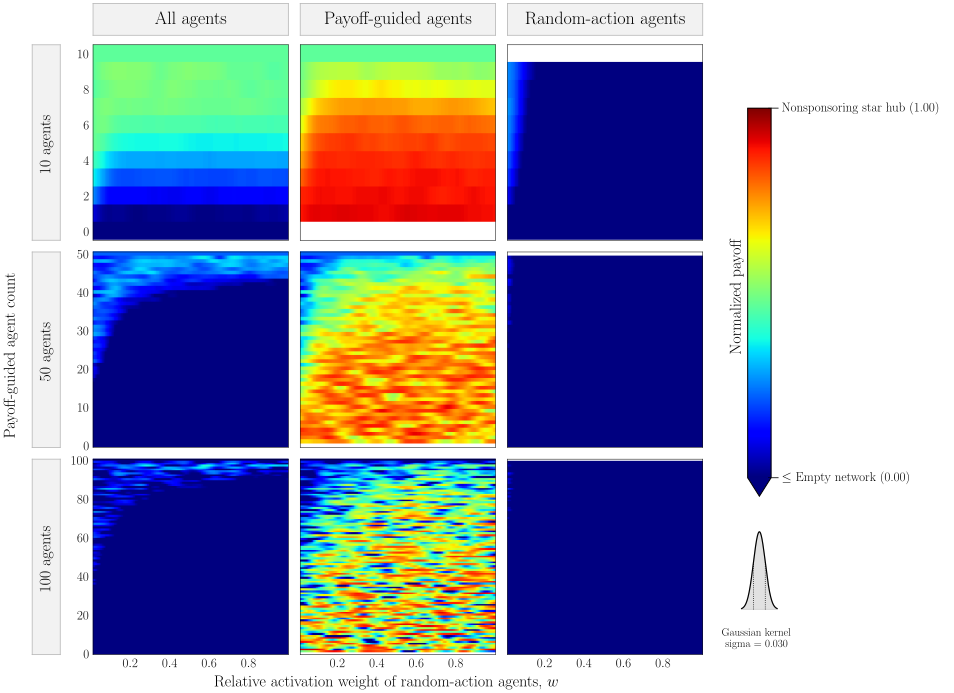

In [5]:
PLOT_MODE = "gaussian"  # "gaussian", "binned", or "raw"
GAUSSIAN_SIGMA = 0.03
BIN_SIZE = 0.1
if PLOT_MODE not in {"gaussian", "binned", "raw"}:
    raise ValueError(f"Unknown PLOT_MODE: {PLOT_MODE!r}")

weight_limits = (
    float(plot_frame["random_activation_weight"].min()),
    float(plot_frame["random_activation_weight"].max()),
)
if PLOT_MODE == "gaussian":
    weight_grid, surfaces = build_surfaces(
        plot_frame, kernel_sigma=GAUSSIAN_SIGMA
    )
elif PLOT_MODE == "binned":
    weight_edges, surfaces = build_binned_surfaces(
        plot_frame, bin_size=BIN_SIZE
    )
    weight_limits = (float(weight_edges[0]), float(weight_edges[-1]))
agent_counts = np.sort(plot_frame["n_agents"].unique())
norm = Normalize(vmin=0.0, vmax=1.0)
base_cmap = plt.get_cmap("jet")
cmap = base_cmap.with_extremes(under=base_cmap(0.0))
fig, axes = plt.subplots(
    len(agent_counts),
    len(population_groups),
    figsize=(13, 11),
    sharex=True,
    sharey="row",
    gridspec_kw={"wspace": 0.06, "hspace": 0.06},
    squeeze=False,
)
fig.subplots_adjust(left=0.10, right=0.752, bottom=0.11, top=0.88)
if PLOT_MODE == "gaussian":
    weight_edges = centers_to_edges(weight_grid)


def plot_payoff_panel(ax, n_agents_value, group):
    if PLOT_MODE in {"gaussian", "binned"}:
        counts, surface = surfaces[(n_agents_value, group)]
        count_edges = centers_to_edges(
            counts, lower=-0.5, upper=float(n_agents_value) + 0.5
        )
        mapped = ax.pcolormesh(
            weight_edges,
            count_edges,
            surface.T,
            shading="flat",
            cmap=cmap,
            norm=norm,
            rasterized=True,
        )
    else:
        panel = plot_frame[
            (plot_frame["n_agents"] == n_agents_value)
            & (plot_frame["population_group"] == group)
        ]
        mapped = ax.scatter(
            panel["random_activation_weight"],
            panel["best_response_count"],
            c=panel["mean_normalized_payoff"],
            s=5,
            linewidths=0,
            cmap=cmap,
            norm=norm,
            rasterized=True,
        )
    ax.set_xlim(*weight_limits)
    ax.set_ylim(-0.5, float(n_agents_value) + 0.5)
    ax.set_box_aspect(1)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
    ax.grid(False)
    ax.tick_params(axis="both", which="both", length=0)
    return mapped


mapped = None
for row, n_agents_value in enumerate(agent_counts):
    for column, group in enumerate(population_groups):
        ax = axes[row, column]
        mapped = plot_payoff_panel(ax, n_agents_value, group)

strip_facecolor = "#f2f2f2"
strip_edgecolor = "#b7b7b7"
for column, group in enumerate(population_groups):
    position = axes[0, column].get_position()
    strip = fig.add_axes([position.x0, position.y1 + 0.012, position.width, 0.04])
    strip.set_facecolor(strip_facecolor)
    strip.text(0.5, 0.5, group, ha="center", va="center", fontsize=18)
    strip.set_xticks([])
    strip.set_yticks([])
    for spine in strip.spines.values():
        spine.set_color(strip_edgecolor)
        spine.set_linewidth(0.8)

for row, n_agents_value in enumerate(agent_counts):
    position = axes[row, 0].get_position()
    strip = fig.add_axes([0.035, position.y0, 0.03, position.height])
    strip.set_facecolor(strip_facecolor)
    strip.text(
        0.5,
        0.5,
        f"{int(n_agents_value)} agents",
        ha="center",
        va="center",
        rotation=90,
        fontsize=16,
    )
    strip.set_xticks([])
    strip.set_yticks([])
    for spine in strip.spines.values():
        spine.set_color(strip_edgecolor)
        spine.set_linewidth(0.8)

fig.text(0.426, 0.07, r"Relative activation weight of random-action agents, $w$", ha="center", fontsize=16)
fig.text(
    0.012,
    0.495,
    "Payoff-guided agent count",
    ha="center",
    va="center",
    rotation=90,
    fontsize=16,
)

assert mapped is not None
colorbar_axis = fig.add_axes([0.80, 0.31, 0.025, 0.49])
has_under_range = bool((plot_frame["mean_normalized_payoff"] < norm.vmin).any())
colorbar = fig.colorbar(
    ScalarMappable(norm=norm, cmap=cmap),
    cax=colorbar_axis,
    extend="min" if has_under_range else "neither",
)
references = [(r"$\leq$ Empty network", 0.0), ("Nonsponsoring star hub", 1.0)]
colorbar_axis.set_yticks(
    [value for _, value in references],
    labels=[""] * len(references),
)
colorbar_axis.minorticks_off()
colorbar_axis.yaxis.tick_right()
colorbar_axis.yaxis.set_label_position("left")
colorbar.set_label("Normalized payoff")
label_transform = colorbar_axis.transAxes
for reference_label, reference_value in references:
    position = float(norm(reference_value))
    colorbar_axis.plot(
        [1.0, 1.32],
        [position, position],
        color="black",
        linewidth=0.8,
        solid_capstyle="butt",
        clip_on=False,
        transform=label_transform,
    )
    colorbar_axis.text(
        1.45,
        position,
        f"{reference_label} ({reference_value:.2f})",
        ha="left",
        va="center",
        fontsize=plt.rcParams["ytick.labelsize"],
        clip_on=False,
        transform=label_transform,
    )
if has_under_range:
    colorbar_axis.add_patch(
        Rectangle(
            (0.0, -0.002),
            1.0,
            0.004,
            transform=colorbar_axis.transAxes,
            facecolor=cmap(0.0),
            edgecolor="none",
            clip_on=False,
            zorder=1.1,
        )
    )
colorbar.outline.set_edgecolor("black")
colorbar.outline.set_linewidth(1.0)

panel_width = axes[-1, -1].get_position().width
colorbar_position = colorbar_axis.get_position()
mode_left = colorbar_position.x0 + colorbar_position.width / 2 - panel_width / 2
mode_axis = fig.add_axes([mode_left, 0.12, panel_width, 0.15])
if PLOT_MODE == "gaussian":
    kernel_center = float(sum(weight_limits) / 2)
    kernel_x = np.linspace(
        kernel_center - 3 * GAUSSIAN_SIGMA,
        kernel_center + 3 * GAUSSIAN_SIGMA,
        200,
    )
    kernel_distance = (kernel_x - kernel_center) / GAUSSIAN_SIGMA
    kernel_weight = np.exp(-0.5 * kernel_distance**2)
    mode_axis.fill_between(kernel_x, kernel_weight, color="black", alpha=0.12)
    mode_axis.plot(kernel_x, kernel_weight, color="black", linewidth=1.2)
    mode_axis.vlines(
        [kernel_center - GAUSSIAN_SIGMA, kernel_center + GAUSSIAN_SIGMA],
        0.0,
        np.exp(-0.5),
        color="black",
        linestyle=":",
        linewidth=0.8,
    )
    mode_axis.text(
        kernel_center,
        -0.24,
        f"Gaussian kernel\nsigma = {GAUSSIAN_SIGMA:.3f}",
        ha="center",
        va="top",
        fontsize=11,
    )
    mode_axis.set_xlim(*weight_limits)
    mode_axis.set_ylim(-0.48, 1.05)
elif PLOT_MODE == "binned":
    mode_axis.text(
        0.5,
        0.5,
        f"X-axis bin means\nbin width = {BIN_SIZE:.1f}",
        ha="center",
        va="center",
        fontsize=12,
        transform=mode_axis.transAxes,
    )
else:
    mode_axis.text(
        0.5,
        0.5,
        "Raw datapoints\n(no smoothing)",
        ha="center",
        va="center",
        fontsize=12,
        transform=mode_axis.transAxes,
    )
mode_axis.axis("off")
plt.show()

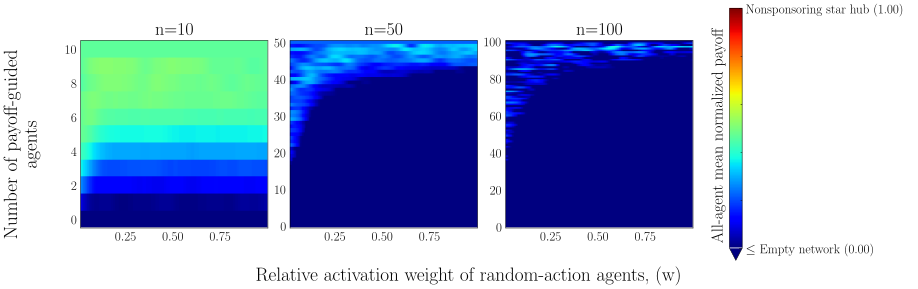

In [6]:
selected_agent_counts = np.array([10, 50, 100])
missing_agent_counts = np.setdiff1d(selected_agent_counts, agent_counts)
if missing_agent_counts.size:
    raise ValueError(
        f"Missing requested agent counts: {missing_agent_counts.tolist()}"
    )

all_agents_fig, all_agents_axes = plt.subplots(
    1,
    selected_agent_counts.size,
    figsize=(12.5, 4.0),
    sharex=True,
    layout="constrained",
)
for ax, n_agents_value in zip(all_agents_axes, selected_agent_counts):
    plot_payoff_panel(ax, n_agents_value, "All agents")
    ax.set_title(f"n={n_agents_value}")

#all_agents_fig.suptitle("All agents")
all_agents_fig.supxlabel("Relative activation weight of random-action agents, (w)")
all_agents_fig.supylabel("Number of payoff-guided\nagents", horizontalalignment='center')
all_agents_colorbar = all_agents_fig.colorbar(
    ScalarMappable(norm=norm, cmap=cmap),
    ax=all_agents_axes,
    extend="min" if has_under_range else "neither",
    pad=0.03,
)
all_agents_colorbar.set_label("All-agent mean normalized payoff")
all_agents_colorbar.ax.yaxis.set_label_position("left")
all_agents_colorbar.set_ticks(
    [value for _, value in references],
    labels=[f"{label} ({value:.2f})" for label, value in references],
)
plt.show()

In [7]:
run_id = result_store_path.stem
figure_output_dir = project_root / "artifacts/figures" / run_id
figure_output_dir.mkdir(parents=True, exist_ok=True)
figure_path = figure_output_dir / f"best_response_proportion_effect_{PLOT_MODE}.pdf"
fig.savefig(figure_path, format="pdf", bbox_inches="tight")
print(f"Saved: {figure_path.relative_to(project_root)}")

all_agents_figure_path = (
    figure_output_dir
    / f"best_response_proportion_effect_all_agents_{PLOT_MODE}.pdf"
)
all_agents_fig.savefig(
    all_agents_figure_path, format="pdf", bbox_inches="tight"
)
print(f"Saved: {all_agents_figure_path.relative_to(project_root)}")

Saved: artifacts/figures/run-20260810T031858/best_response_proportion_effect_gaussian.pdf
Saved: artifacts/figures/run-20260810T031858/best_response_proportion_effect_all_agents_gaussian.pdf
